# Báo cáo ngắn về bộ dữ liệu FPT — LAB01

**Mục đích:** mô tả dữ liệu lịch sử giao dịch cổ phiếu FPT và thống kê cơ bản phục vụ thực hành phân tích dữ liệu.

**Tệp sử dụng:** `FPT_stock.csv` trong `LAB01/Bai02`. Mỗi dòng tương ứng một phiên giao dịch.
Theo mã thu thập `Bai02.py`, dữ liệu được lấy từ [trang lịch sử giao dịch FPT](https://lichsugia.site/lich-su-giao-dich/FPT.html), trong khoảng yêu cầu 09/10/2021–09/10/2026. Báo cáo này chỉ đọc tệp đã lưu, không thu thập lại.

**Tổng quan:** 1.244 dòng, 9 cột, một mã chứng khoán FPT; ngày thực tế từ **11/10/2021 đến 09/10/2026**. Các ngày là phiên giao dịch, không phải chuỗi ngày lịch liên tục.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Tìm CSV khi mở notebook tại Bai02, LAB01 hoặc thư mục gốc repo.
folder = Path.cwd()
paths = [folder / "FPT_stock.csv", folder / "Bai02/FPT_stock.csv",
         folder / "LAB01/Bai02/FPT_stock.csv"]
path = next(p for p in paths if p.exists())
df = pd.read_csv(path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
pd.options.display.float_format = "{:,.2f}".format

print(f"Số dòng: {len(df):,} | Số cột: {df.shape[1]}")
print("Mã chứng khoán:", ", ".join(df["symbol"].unique()))
print("Thời gian:", df["date"].min().strftime("%d/%m/%Y"),
      "đến", df["date"].max().strftime("%d/%m/%Y"))
display(df.head())

Số dòng: 1,244 | Số cột: 9
Mã chứng khoán: FPT
Thời gian: 11/10/2021 đến 09/10/2026


,symbol,date,open,high,low,close,adjusted_close,volume,change_percent
0,FPT,2021-10-11,99.00,99.30,98.30,99.20,49.82,2295500,0.30
1,FPT,2021-10-12,99.20,99.20,98.50,99.00,49.72,1125300,-0.20
2,FPT,2021-10-13,99.00,101.50,98.50,99.40,49.92,3232500,0.40
3,FPT,2021-10-14,99.40,100.00,98.40,98.80,49.62,1824200,-0.60
4,FPT,2021-10-15,99.40,100.10,98.40,98.90,49.67,1702500,0.10


## 1. Mô tả các thuộc tính

| Thuộc tính | Kiểu dữ liệu khi đọc | Ý nghĩa |
|---|---|---|
| `symbol` | Chuỗi | Mã chứng khoán FPT |
| `date` | Ngày tháng | Ngày giao dịch |
| `open` | Số thực | Giá mở cửa |
| `high` | Số thực | Giá cao nhất trong phiên |
| `low` | Số thực | Giá thấp nhất trong phiên |
| `close` | Số thực | Giá đóng cửa |
| `adjusted_close` | Số thực | Giá đóng cửa đã điều chỉnh theo nguồn dữ liệu |
| `volume` | Số nguyên | Khối lượng cổ phiếu giao dịch trong phiên |
| `change_percent` | Số thực | Phần trăm thay đổi giá theo nguồn dữ liệu |

Giá được giữ nguyên thang đo trong CSV vì tệp không ghi rõ đơn vị giá. `change_percent = 1` có nghĩa là 1%, không phải 100%. `close` và `adjusted_close` là hai đại lượng khác nhau; nên dùng giá điều chỉnh khi phân tích biến động dài hạn.

## 2. Thống kê mô tả

Bảng dưới gồm số quan sát, trung bình, độ lệch chuẩn, nhỏ nhất, các tứ phân vị và lớn nhất của 7 thuộc tính số. Q2 là trung vị.

In [2]:
numeric_columns = ["open", "high", "low", "close", "adjusted_close", "volume", "change_percent"]
statistics = df[numeric_columns].describe().T
statistics.columns = ["Số mẫu", "Trung bình", "Độ lệch chuẩn", "Nhỏ nhất", "Q1", "Trung vị", "Q3", "Lớn nhất"]
display(statistics.round(2))

,Số mẫu,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1,Trung vị,Q3,Lớn nhất
open,"1,244.00",99.40,22.08,59.50,81.60,95.50,114.00,154.10
high,"1,244.00",100.50,22.27,60.00,82.07,96.40,115.80,156.00
low,"1,244.00",98.31,21.91,57.50,81.00,94.65,112.60,153.40
close,"1,244.00",99.36,22.12,57.90,81.60,95.50,114.08,154.30
adjusted_close,"1,244.00",73.33,23.40,40.50,49.60,70.80,94.68,130.76
volume,"1,244.00","4,459,502.97","4,486,118.14","221,000.00","1,385,675.00","2,919,900.00","6,081,800.00","47,733,100.00"
change_percent,"1,244.00",0.04,1.76,-6.99,-0.87,0.00,0.86,6.97


## 3. Kiểm tra chất lượng dữ liệu

Kiểm tra giá trị thiếu, bản ghi trùng, ngày không hợp lệ và tính hợp lý cơ bản của giá/khối lượng. Các kiểm tra này không tự xác nhận rằng đã thu thập đủ mọi phiên giao dịch.

In [3]:
invalid_ohlc = ((df["high"] < df[["open", "close", "low"]].max(axis=1)) |
                (df["low"] > df[["open", "close", "high"]].min(axis=1)))
checks = pd.DataFrame({
    "Kiểm tra": ["Tổng giá trị thiếu", "Dòng có giá trị thiếu", "Bản ghi trùng hoàn toàn",
                 "Trùng ngày giao dịch", "Ngày không hợp lệ", "Dòng có giá không dương",
                 "Dòng có khối lượng âm", "Dòng có khối lượng bằng 0", "Dòng giá OHLC không hợp lý"],
    "Số lượng": [int(df.isna().sum().sum()), int(df.isna().any(axis=1).sum()),
                int(df.duplicated().sum()), int(df["date"].duplicated().sum()),
                int(df["date"].isna().sum()),
                int((df[["open", "high", "low", "close", "adjusted_close"]] <= 0).any(axis=1).sum()),
                int((df["volume"] < 0).sum()), int((df["volume"] == 0).sum()), int(invalid_ohlc.sum())]
})
display(checks)

,Kiểm tra,Số lượng
0,Tổng giá trị thiếu,0
1,Dòng có giá trị thiếu,0
2,Bản ghi trùng hoàn toàn,0
3,Trùng ngày giao dịch,0
4,Ngày không hợp lệ,0
5,Dòng có giá không dương,0
6,Dòng có khối lượng âm,0
7,Dòng có khối lượng bằng 0,0
8,Dòng giá OHLC không hợp lý,0


## 4. Minh họa dữ liệu theo thời gian

Biểu đồ giá đóng cửa điều chỉnh và khối lượng giúp quan sát xu hướng giá, mức độ biến động và các phiên giao dịch đột biến.

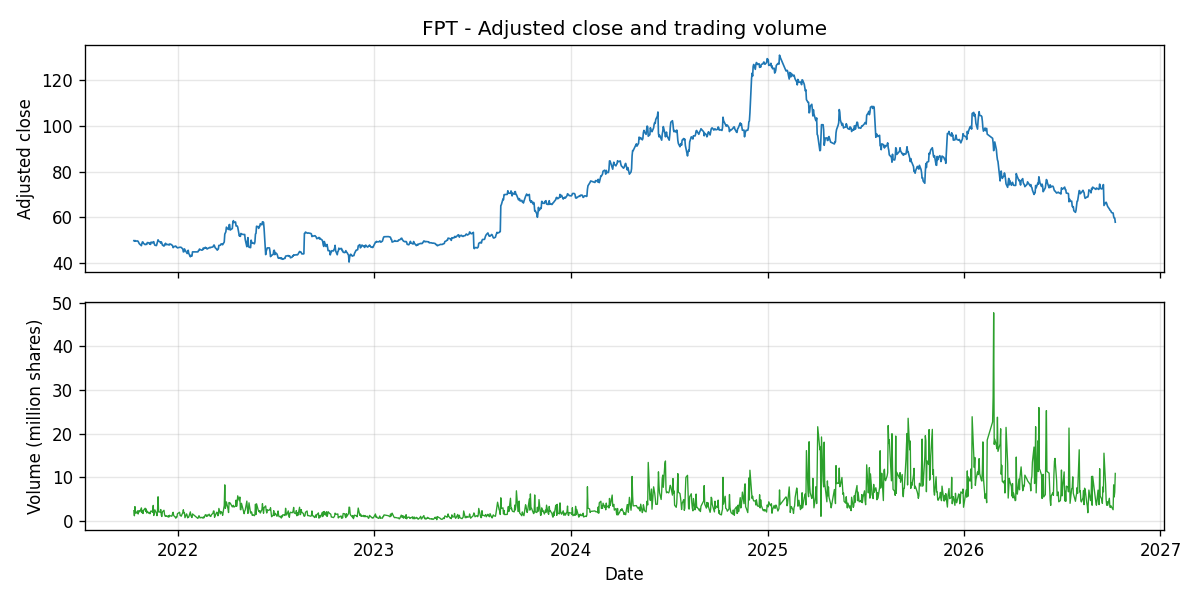

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(df["date"], df["adjusted_close"], linewidth=1, color="tab:blue")
axes[0].set_title("FPT - Adjusted close and trading volume")
axes[0].set_ylabel("Adjusted close")
axes[1].plot(df["date"], df["volume"] / 1_000_000, linewidth=0.8, color="tab:green")
axes[1].set_ylabel("Volume (million shares)")
axes[1].set_xlabel("Date")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Nhận xét ngắn

- Không phát hiện giá trị thiếu, dòng trùng, ngày trùng hoặc vi phạm quy tắc giá OHLC trong các kiểm tra trên.
- Giá đóng cửa trung bình **99,36**, nhỏ nhất **57,90**, lớn nhất **154,30**; giá đóng cửa điều chỉnh trung bình **73,33**, trong khoảng **40,50–130,76** (theo thang đo của CSV).
- Khối lượng trung bình khoảng **4,46 triệu cổ phiếu/phiên**, trung vị **2,92 triệu**, lớn nhất **47,73 triệu**. Trung bình cao hơn trung vị cho thấy một số phiên khối lượng lớn kéo mức trung bình lên.
- Biến động giá theo nguồn có trung bình **0,044%/phiên**, nhỏ nhất **-6,99%**, lớn nhất **6,97%**; độ lệch chuẩn khoảng **1,76 điểm phần trăm**.
- Dữ liệu phù hợp để thực hành thống kê, trực quan hóa và xây dựng đặc trưng theo thời gian. Khi làm mô hình, nên chia train/test theo thứ tự ngày và tránh dùng thông tin phiên tương lai làm đầu vào.